In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys

In [2]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [3]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../..")))
from ddpg.buffer import *

pygame 2.6.0 (SDL 2.28.4, Python 3.8.2)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [4]:
work_folder = 'federated'
saving_folder = 'eta_crit'
os.chdir(work_folder + '/' + saving_folder)

In [5]:
file_path = 'parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.01
decay_rate = 0.015
max_action = 7
delta_special = 0.3
beta_special = 4.5
n_special = 10
t_transient = 200
tmax = 1200
batch_size = 64
gamma = 0.99
max_size = 1000000
state_dim = (3,)
action_dim = 1
action_bound = 1
actor_lr = 1e-05
critic_lr = 0.0001
tau = 0.001
noise = 0.05
weight_decay = 0.01


In [6]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, max_action,
                  delta_special, beta_special, tmax, n_special, t_transient)

buffer = ReplayBuffer(max_size, state_dim, action_dim)

In [7]:
if work_folder=='global':
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
    from ddpg_ants_global import *
    config_net_file = saving_folder + '/' + 'networks_global.yaml'
    ddpg_ants = DDPG_ants_global(env, buffer,
                 gamma, action_bound, actor_lr, critic_lr, tau, batch_size, noise, weight_decay, config_net_file)

if work_folder=='federated':
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
    from ddpg_ants_federated import *
    config_net_file = saving_folder + '/' + 'networks_federated.yaml'
    ddpg_ants = DDPG_ants_federated(env, buffer,
                 gamma, action_bound, actor_lr, critic_lr, tau, batch_size, noise, weight_decay, config_net_file)

if work_folder=='field':
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
    from ddpg_ants_field import *
    config_net_file = saving_folder + '/' + 'networks_field.yaml'
    ddpg_ants = DDPG_ants_field(env, buffer,
                 gamma, action_bound, actor_lr, critic_lr, tau, batch_size, noise, weight_decay, config_net_file)


In [8]:
env.reset_objects()
env.transient()

reward_collection = []
op_list = []
op_avg_list = []
done = False

while not done:

    action = np.ones(10)*0.3
    new_state, reward, done = ddpg_ants.execute_action(action)
    op_list.append(env.order_parameter_p().copy())
    op_avg_list.append(env.OP.copy())
    reward_collection.append(reward)

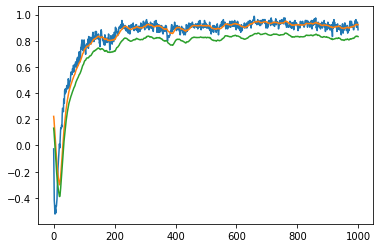

In [9]:
plt.plot(op_list)
plt.plot(op_avg_list)
if work_folder=='global': 
    plt.plot(reward_collection)
else:
    plt.plot(np.mean(reward_collection, axis=1))

In [10]:
sim_res = ddpg_ants.simulation_episode(np.ones(10)*0.3)

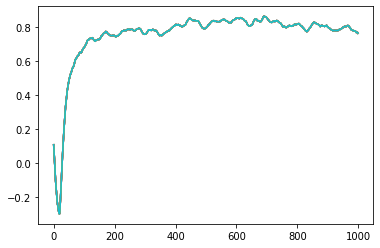

In [11]:
plt.plot(sim_res)

In [12]:
sim_results = []
if work_folder=='global':
    policies = np.ones((10,11))*np.linspace(0,1,11)
if work_folder=='federated':
    policies = np.ones((10,11))*np.linspace(0,1,11)
    
realizations = 10

for p in policies.T:
    for _ in range(realizations):
        sim_results.append(ddpg_ants.simulation_episode(p))

sim_results = np.array(sim_results)

sim_results.shape

(110, 1000, 10)

In [13]:
sim_res = sim_results

In [16]:
sim_results = np.mean(sim_res.reshape(11,10,1000,10), axis=(1))

In [18]:
sim_results.shape

(11, 1000, 10)

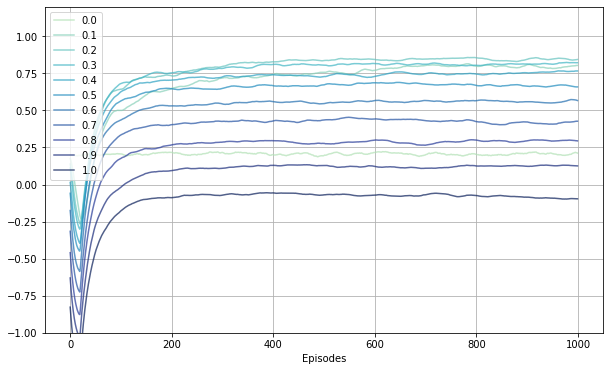

In [19]:
import matplotlib.cm as cm

fig, ax1 = plt.subplots(figsize=(10,6))

cmap = cm.get_cmap('YlGnBu')

for i in range(len(sim_results)):
    if work_folder=='global':
        ax1.plot(sim_results[i], label=i/10, c=cmap((i+4)/14), alpha=0.7)

    if work_folder=='federated':
        ax1.plot(np.mean(sim_results[i], axis=1), label=i/10, c=cmap((i+4)/14), alpha=0.7)
ax1.grid()
ax1.legend(loc='upper left')
ax1.set_ylim(-1,1.2)
ax1.set_xlabel('Episodes')

plt.show()

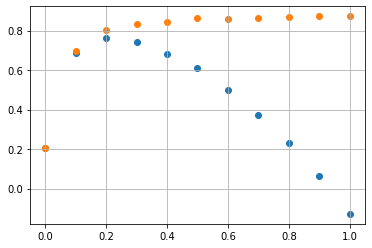

In [22]:
if work_folder=='global':
    plt.scatter(np.linspace(0,1,11), sim_results.mean(axis=(1)))
    plt.scatter(np.linspace(0,1,11), sim_results.mean(axis=(1))+np.array([np.linalg.norm(np.ones(10)*i)**2/10 for i in np.linspace(0,1,11)]))
    #plt.scatter(np.linspace(0,1,11), sim_results.mean(axis=(1))+np.array([i**2 for i in np.linspace(0,1,11)]))

if work_folder=='federated':
    plt.scatter(np.linspace(0,1,11), sim_results.mean(axis=(1,2)))
    plt.scatter(np.linspace(0,1,11), sim_results.mean(axis=(1,2))+np.array([i**2 for i in np.linspace(0,1,11)]))
    
plt.grid()
#plt.ylim(0,1)
plt.show()
